## Project 2: Disease Prediction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

In [12]:
data = pd.read_excel('Disease.xlsx')

## Data Understanding

In [13]:
data.shape

(699, 10)

In [14]:
data.head()

,Clump_thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,5,1,1,1,2,1.0,3,1,1,0
1,5,4,4,5,7,10.0,3,2,1,0
2,3,1,1,1,2,2.0,3,1,1,0
3,6,8,8,1,3,4.0,3,7,1,0
4,4,1,1,3,2,1.0,3,1,1,0


In [15]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Clump_thickness              699 non-null    int64  
 1   Uniformity_Cell_Size         699 non-null    int64  
 2   Uniformity_Cell_Shape        699 non-null    int64  
 3   Marginal_Adhesion            699 non-null    int64  
 4   Single_Epithelial_Cell_Size  699 non-null    int64  
 5   Bare_Nuclei                  683 non-null    float64
 6   Bland_Chromatin              699 non-null    int64  
 7   Normal_Nucleoli              699 non-null    int64  
 8   Mitoses                      699 non-null    int64  
 9   Class                        699 non-null    int64  
dtypes: float64(1), int64(9)
memory usage: 54.7 KB


In [16]:
np.sum(data.duplicated())

np.int64(236)

In [17]:
data.drop_duplicates(inplace=True)
np.sum(data.duplicated())

np.int64(0)

In [18]:
data.info()

<class 'pandas.DataFrame'>
Index: 463 entries, 0 to 698
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Clump_thickness              463 non-null    int64  
 1   Uniformity_Cell_Size         463 non-null    int64  
 2   Uniformity_Cell_Shape        463 non-null    int64  
 3   Marginal_Adhesion            463 non-null    int64  
 4   Single_Epithelial_Cell_Size  463 non-null    int64  
 5   Bare_Nuclei                  449 non-null    float64
 6   Bland_Chromatin              463 non-null    int64  
 7   Normal_Nucleoli              463 non-null    int64  
 8   Mitoses                      463 non-null    int64  
 9   Class                        463 non-null    int64  
dtypes: float64(1), int64(9)
memory usage: 39.8 KB


In [19]:
data.isnull().sum()

Clump_thickness                 0
Uniformity_Cell_Size            0
Uniformity_Cell_Shape           0
Marginal_Adhesion               0
Single_Epithelial_Cell_Size     0
Bare_Nuclei                    14
Bland_Chromatin                 0
Normal_Nucleoli                 0
Mitoses                         0
Class                           0
dtype: int64

### Handaling missing values

In [20]:
data.fillna(data.median(), inplace=True)

data.isna().sum()

Clump_thickness                0
Uniformity_Cell_Size           0
Uniformity_Cell_Shape          0
Marginal_Adhesion              0
Single_Epithelial_Cell_Size    0
Bare_Nuclei                    0
Bland_Chromatin                0
Normal_Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64

## EDA

### Univariate analysis

In [21]:
numeric_vars = range(0,9)

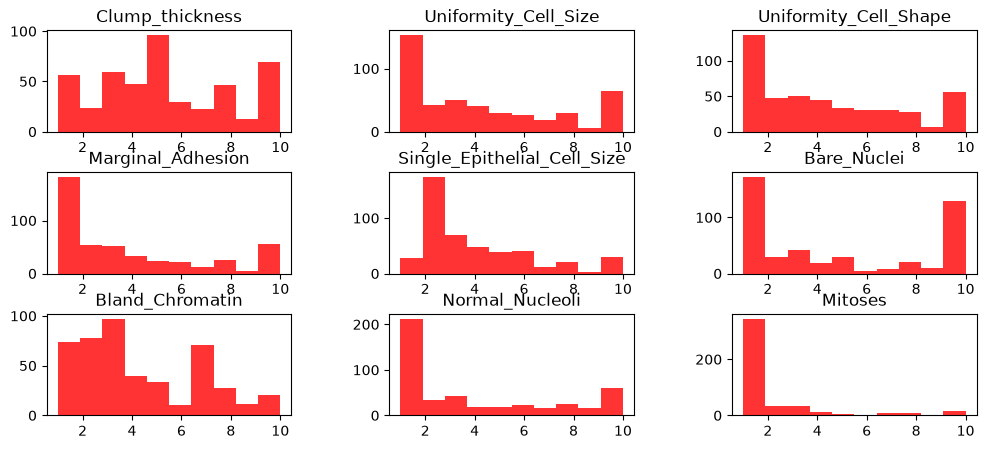

In [22]:
plt.figure(figsize = (12, 5))
plt.subplots_adjust(hspace = 0.4, wspace = 0.4)

for i in range(1, len(numeric_vars)+1):
    plt.subplot(3, 3, i)
    plt.hist(x = data.iloc[: , numeric_vars[i-1]], alpha = 0.8, color = 'red')
    plt.title(data.columns[numeric_vars[i-1]])
plt.show()    

### Multivariate analysis

In [23]:
#Correlation analysis
round(data.iloc[:, numeric_vars].corr(), 2)

,Clump_thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses
Clump_thickness,1.00,0.58,0.59,0.38,0.43,0.51,0.50,0.45,0.30
Uniformity_Cell_Size,0.58,1.00,0.88,0.64,0.69,0.59,0.71,0.66,0.40
Uniformity_Cell_Shape,0.59,0.88,1.00,0.61,0.65,0.62,0.69,0.65,0.38
Marginal_Adhesion,0.38,0.64,0.61,1.00,0.53,0.59,0.61,0.51,0.36
Single_Epithelial_Cell_Size,0.43,0.69,0.65,0.53,1.00,0.48,0.55,0.56,0.43
Bare_Nuclei,0.51,0.59,0.62,0.59,0.48,1.00,0.60,0.47,0.26
Bland_Chromatin,0.50,0.71,0.69,0.61,0.55,0.60,1.00,0.61,0.28
Normal_Nucleoli,0.45,0.66,0.65,0.51,0.56,0.47,0.61,1.00,0.37
Mitoses,0.30,0.40,0.38,0.36,0.43,0.26,0.28,0.37,1.00


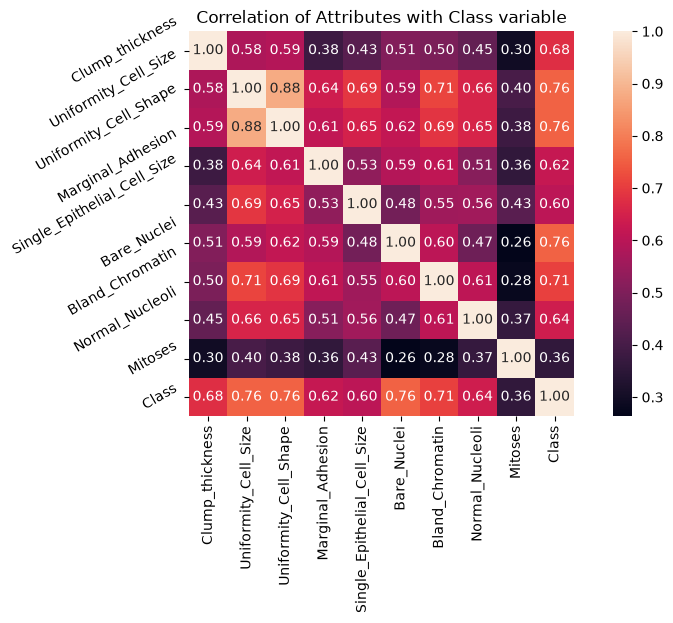

In [24]:
plt.figure(figsize=(10,5))
plt.title('Correlation of Attributes with Class variable')
a = sns.heatmap(data.corr(), square=True, annot=True, fmt='.2f', linecolor='white')
a.set_xticklabels(a.get_xticklabels(), rotation=90)
a.set_yticklabels(a.get_yticklabels(), rotation=30)           
plt.show()

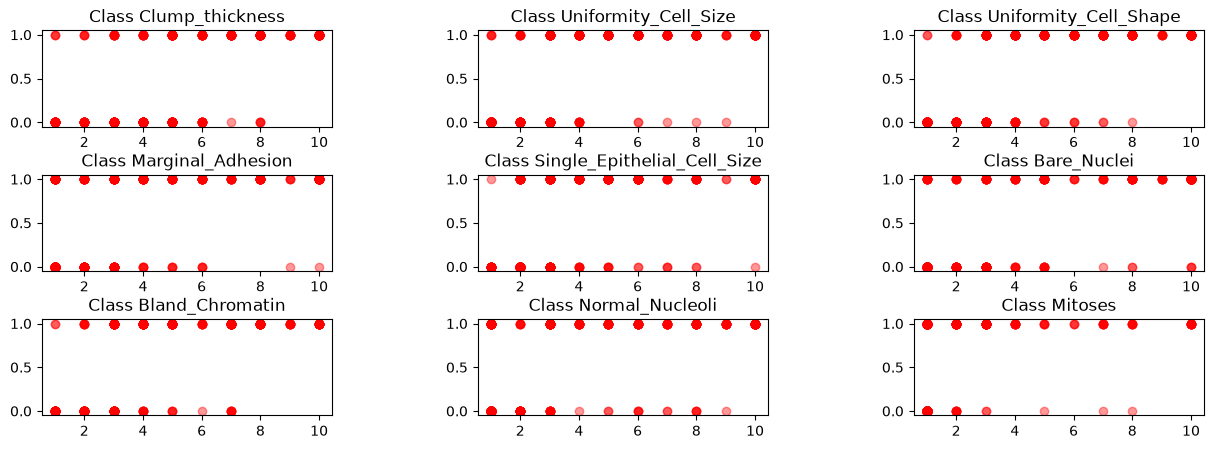

In [25]:
#Scatter plot

plt.figure(figsize = (15, 5))
plt.subplots_adjust(hspace = 0.5, wspace = 0.5)

for i in range(1, len(numeric_vars)+1):
    plt.subplot(3, 3, i)
    plt.scatter(x = data.iloc[: , numeric_vars[i - 1]], y = data['Class'], alpha = 0.4, color = 'red')
    plt.title('Class ' + data.columns[numeric_vars[i - 1]])
plt.show()

In [26]:
data.corr()['Class'].sort_values(ascending=False)

Class                          1.000000
Uniformity_Cell_Shape          0.757932
Uniformity_Cell_Size           0.757623
Bare_Nuclei                    0.756155
Bland_Chromatin                0.707166
Clump_thickness                0.675748
Normal_Nucleoli                0.639909
Marginal_Adhesion              0.622371
Single_Epithelial_Cell_Size    0.604709
Mitoses                        0.360433
Name: Class, dtype: float64

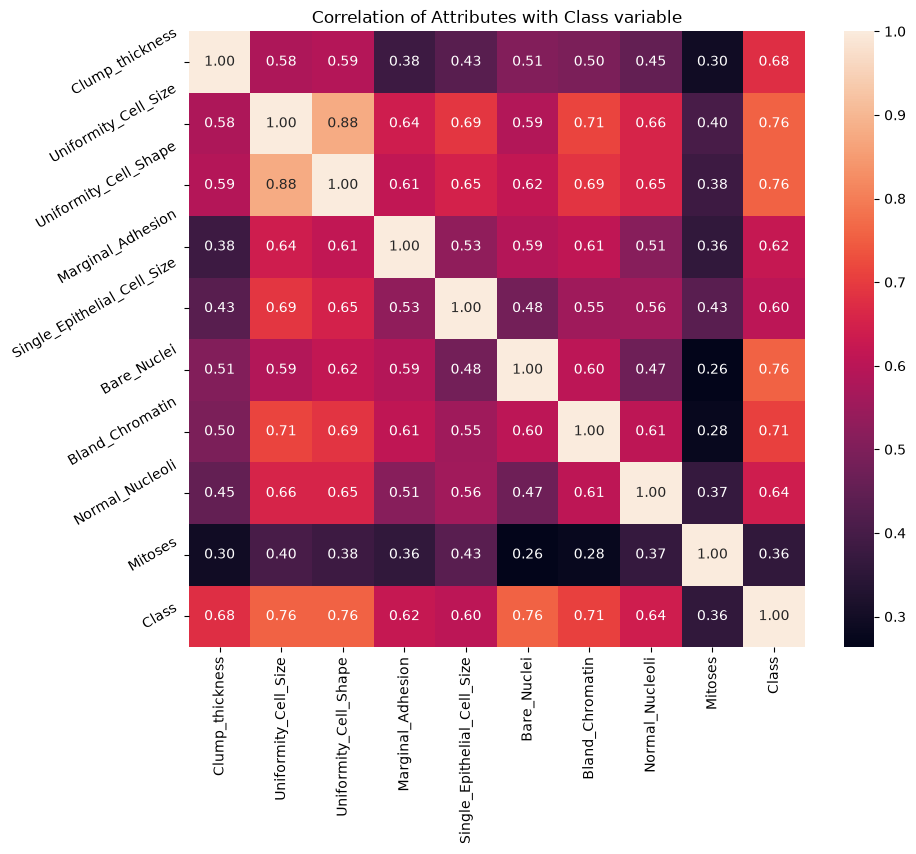

In [27]:
plt.figure(figsize=(10,8))
plt.title('Correlation of Attributes with Class variable')
a = sns.heatmap(data.corr(), square=True, annot=True, fmt='.2f', linecolor='white')
a.set_xticklabels(a.get_xticklabels(), rotation=90)
a.set_yticklabels(a.get_yticklabels(), rotation=30)           
plt.show()

### Outlier Detection

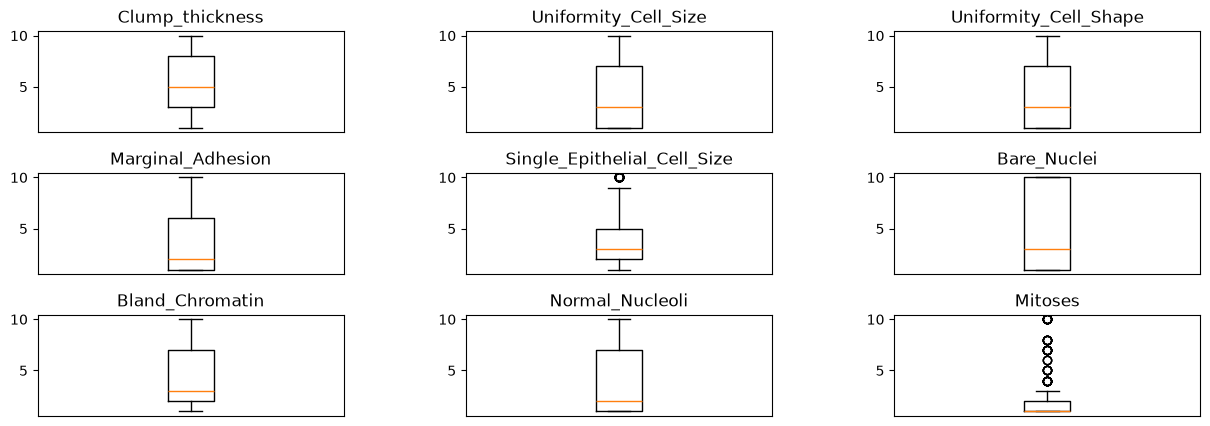

In [28]:
#Boxplot of numeric variables
import matplotlib.pyplot as plt

plt.figure(figsize = (15, 5))
plt.subplots_adjust(hspace = 0.4, wspace = 0.4)

for i in range(1, len(numeric_vars)+1):
    plt.subplot(3, 3, i)
    plt.boxplot(data.iloc[: , numeric_vars[i - 1]])
    plt.xticks([]) #remove the xticks 
    plt.title(data.columns[numeric_vars[i - 1]])
plt.show()

In [29]:
def Outlier_Removal(data, column):
    # Make a copy of the data to avoid modifying the original
    df = data.copy()
    
    # Reset the index to ensure continuous indexing
    df = df.reset_index(drop=True)
    
    # Calculate Q1, Q3 and IQR
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Filter out outliers
    df_filtered = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    
    # Reset index again after filtering
    df_filtered = df_filtered.reset_index(drop=True)
    
    return df_filtered

In [30]:
print("Old Shape: ", data.shape)

Old Shape:  (463, 10)


In [31]:
data.columns

Index(['Clump_thickness', 'Uniformity_Cell_Size', 'Uniformity_Cell_Shape',
       'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei',
       'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses', 'Class'],
      dtype='str')

In [32]:
Data_cleaned = Outlier_Removal(data, 'Mitoses')
Data_cleaned.shape

(411, 10)

In [33]:
Data_cleaned = Outlier_Removal(Data_cleaned, 'Single_Epithelial_Cell_Size')
Data_cleaned.shape

(393, 10)

## Data Preparing

In [34]:
X = data.drop(['Class'], axis=1)
y = data['Class']

### Train - Test Split

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 0)


In [36]:
X_train.shape, X_test.shape

((324, 9), (139, 9))

## KNN

In [37]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

params = {'n_neighbors':[3,4,5,6,7,8,9,10,11,12]}

knn = KNeighborsClassifier()

grid1 = GridSearchCV(knn, params, cv=5)
grid1.fit(X_train_scaled, y_train)
grid1.best_params_

{'n_neighbors': 3}

In [38]:
# Build the best KNN classifrier

Model_1 = KNeighborsClassifier(n_neighbors = grid1.best_params_['n_neighbors'])

#Fit the kNN classifier on the train
Model_1.fit(X_train_scaled, y_train)

#Predict train data set
y_train_prediction_1 = pd.Series(Model_1.predict(X_train_scaled), index = X_train.index)
y_train_prediction_1

457    1
323    1
412    1
604    1
309    0
      ..
434    1
239    1
132    1
50     1
215    1
Length: 324, dtype: int64

In [39]:
#Model evaluation on train - model 1

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import fbeta_score
from sklearn.metrics import confusion_matrix

print('Accuracy Train: {:.2f}'.format(accuracy_score(y_train, y_train_prediction_1)))
print('Precision Train: {:.2f}'.format(precision_score(y_train, y_train_prediction_1)))
print('Recall Train: {:.2f}'.format(recall_score(y_train, y_train_prediction_1)))
print('F1 Score Train: {:.2f}'.format(f1_score(y_train, y_train_prediction_1)))
print('F2 Score Train: {:.2f}'.format(fbeta_score(y_train, y_train_prediction_1, beta = 2)))

Accuracy Train: 0.96
Precision Train: 0.96
Recall Train: 0.96
F1 Score Train: 0.96
F2 Score Train: 0.96


In [40]:
#Predict test data set
y_test_prediction_1 = pd.Series(Model_1.predict(X_test_scaled), index = X_test.index)

Results = pd.DataFrame({'Accuracy': round(accuracy_score(y_test, y_test_prediction_1), 2),
                        'Precision': round(precision_score(y_test, y_test_prediction_1), 2),
                        'Recall': round(recall_score(y_test, y_test_prediction_1), 2),
                        'F1 Score': round(f1_score(y_test, y_test_prediction_1), 2),
                        'F2 Score': round(fbeta_score(y_test, y_test_prediction_1, beta = 2), 2)
                       }, 
                       index = ['kNN - Tuned'])

Results

,Accuracy,Precision,Recall,F1 Score,F2 Score
kNN - Tuned,0.94,0.94,0.93,0.93,0.93


In [41]:
Model_1.predict_proba(X_test_scaled)[:,1]

array([1.        , 0.66666667, 0.        , 0.        , 0.66666667,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 1.        , 1.        , 0.        , 0.        ,
       0.        , 0.66666667, 0.33333333, 0.        , 0.        ,
       0.66666667, 0.        , 1.        , 0.        , 0.33333333,
       1.        , 0.        , 0.        , 0.        , 1.        ,
       0.66666667, 0.        , 0.        , 1.        , 1.        ,
       1.        , 0.        , 0.        , 1.        , 0.        ,
       1.        , 1.        , 0.        , 1.        , 1.        ,
       0.        , 1.        , 0.        , 0.66666667, 0.66666667,
       0.        , 0.33333333, 1.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 1.        , 1.        ,
       0.        , 1.        , 0.33333333, 1.        , 0.33333333,
       0.        , 0.        , 1.        , 1.        , 0.        ,
       1.        , 0.        , 1.        , 1.        , 1.     

## Logistics Regression

In [42]:
X_cleaned = Data_cleaned.drop(['Class'], axis=1)
y_cleaned = Data_cleaned['Class']

X_train_cleaned, X_test_cleaned, y_train_cleaned, y_test_cleaned = train_test_split(X_cleaned, y_cleaned, test_size = 0.3, random_state = 0)

In [43]:
#Logistic regression - Model 2
from sklearn.linear_model import LogisticRegression

Model_2 = LogisticRegression(penalty = None,
                             random_state = 1234,
                             max_iter = 100,
                             solver = 'lbfgs')

#Fit the logistic regression on the train
Model_2.fit(X_train_cleaned, y_train_cleaned)
print(Model_2.coef_)
print(Model_2.intercept_)

[[0.43996335 0.05348625 0.16611227 0.1775809  0.0152063  0.40275276
  0.39175311 0.18478573 0.00165528]]
[-7.95633399]


In [44]:
y_train_prob_2 = Model_2.predict_proba(X_train_cleaned)

In [45]:
y_train_prob_2

array([[9.72728216e-01, 2.72717836e-02],
       [6.31739447e-01, 3.68260553e-01],
       [9.56081471e-01, 4.39185288e-02],
       [2.48201047e-02, 9.75179895e-01],
       [9.85170504e-01, 1.48294960e-02],
       [9.70998740e-01, 2.90012605e-02],
       [9.83823668e-01, 1.61763317e-02],
       [9.93887751e-01, 6.11224856e-03],
       [9.89215689e-01, 1.07843110e-02],
       [9.96556675e-01, 3.44332516e-03],
       [3.35369129e-03, 9.96646309e-01],
       [3.35598338e-02, 9.66440166e-01],
       [6.51632844e-04, 9.99348367e-01],
       [9.57892463e-01, 4.21075367e-02],
       [9.60670892e-01, 3.93291080e-02],
       [1.06290186e-01, 8.93709814e-01],
       [9.90715119e-01, 9.28488083e-03],
       [2.35243748e-03, 9.97647563e-01],
       [5.69066087e-04, 9.99430934e-01],
       [9.89832593e-01, 1.01674074e-02],
       [9.75835794e-01, 2.41642061e-02],
       [9.89788096e-01, 1.02119039e-02],
       [9.96838262e-01, 3.16173822e-03],
       [9.40417757e-01, 5.95822430e-02],
       [9.698419

In [46]:
from sklearn.metrics import roc_curve, auc

def plot_roc(y_true, y_scores):
    # Calculate ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)

    #Calculate area under curve (AUC)
    print('AUC : {r: 0.2f}'.format(r = auc(fpr, tpr)))
    
    # Create figure
    plt.figure(figsize=(8, 6))
    
    # Plot ROC curve
    plt.plot(fpr, tpr, color='blue', lw=2, 
             label=f'ROC curve (AUC = {roc_auc:.3f})')
    
    # Plot diagonal reference line
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    
    # Customize plot
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC)')
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
    
    return plt

AUC :  0.99


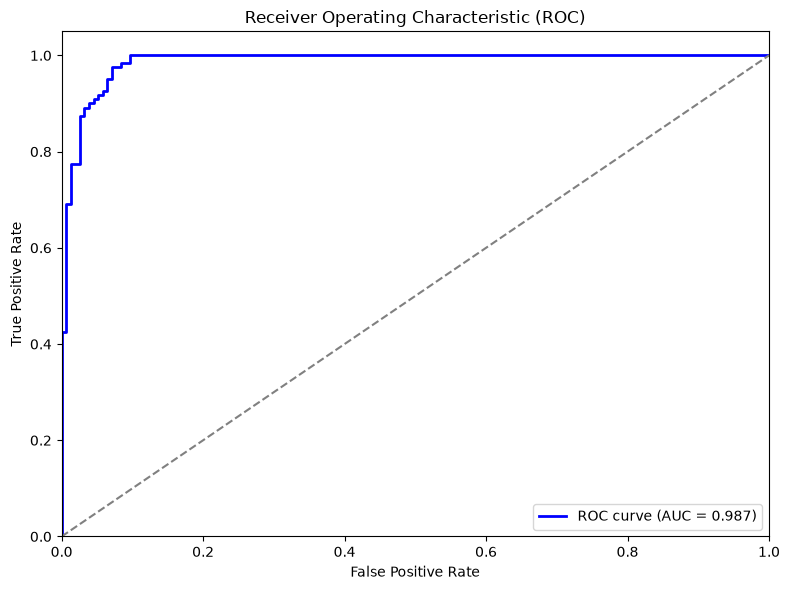

<module 'matplotlib.pyplot' from 'C:\\Users\\HP ZBOOK STUDIO\\anaconda3\\Lib\\site-packages\\matplotlib\\pyplot.py'>

In [47]:
#Plot ROC curve - model 1
plot_roc(y_train_cleaned, y_train_prob_2[:, 1])

In [48]:
def find_cutoff(y_true, y_prob):
    """
    Find the optimal probability cutoff point for a classification model
    using Youden's index 
    
    Parameters:
    -----------
    y_true : array-like
        True binary labels
    y_prob : array-like
        Predicted probabilities
        
    Returns:
    --------
    optimal_cutoff : float
        Optimal threshold value
    """
    # Calculate ROC curve
    fpr, tpr, threshold = roc_curve(y_true, y_prob)
    
    # Calculate Youden's J statistic
    j_scores = tpr - fpr
    
    # Find the optimal cutoff
    best_idx = np.argmax(j_scores)
    optimal_cutoff = threshold[best_idx]
    
    # Return the rounded optimal cutoff
    return round(optimal_cutoff, 3)

In [49]:
#Find the optimal cut-off
cutoff = find_cutoff(y_train_cleaned, y_train_prob_2[:, 1])
cutoff

np.float64(0.265)

In [50]:
#Predict class on train
y_train_prediction_2 = pd.Series([1 if _ > cutoff else 0 for _ in y_train_prob_2[:, 1]], 
                           index = y_train_cleaned.index)
y_train_prediction_2

327    0
173    1
159    0
142    1
217    0
      ..
323    1
192    0
117    0
47     1
172    1
Length: 275, dtype: int64

In [51]:
print('Accuracy Train: {:.2f}'.format(accuracy_score(y_train_cleaned, y_train_prediction_2)))
print('Precision Train: {:.2f}'.format(precision_score(y_train_cleaned, y_train_prediction_2)))
print('Recall Train: {:.2f}'.format(recall_score(y_train_cleaned, y_train_prediction_2)))
print('F1 Score Train: {:.2f}'.format(f1_score(y_train_cleaned, y_train_prediction_2)))
print('F2 Score Train: {:.2f}'.format(fbeta_score(y_train_cleaned, y_train_prediction_2, beta = 2)))

Accuracy Train: 0.95
Precision Train: 0.91
Recall Train: 0.97
F1 Score Train: 0.94
F2 Score Train: 0.96


In [52]:
#Predict probability in the test
y_test_prob_2 = Model_2.predict_proba(X_test_cleaned)

#Predict class in the test
y_test_prediction_2 = pd.Series([1 if _ > cutoff else 0 for _ in y_test_prob_2[:, 1]])
y_test_prediction_2

0      0
1      0
2      1
3      0
4      0
      ..
113    0
114    1
115    0
116    1
117    0
Length: 118, dtype: int64

In [53]:
Results = pd.concat([Results, 
                             pd.DataFrame({'Accuracy': round(accuracy_score(y_test_cleaned, y_test_prediction_2), 2),
                                          'Precision': round(precision_score(y_test_cleaned, y_test_prediction_2), 2),
                                          'Recall': round(recall_score(y_test_cleaned, y_test_prediction_2), 2),
                                          'F1 Score' : round(f1_score(y_test_cleaned, y_test_prediction_2), 2),
                                          'F2 Score' : round(fbeta_score(y_test_cleaned, y_test_prediction_2, beta = 2), 2)},                         
                                           index = ['Logistic Regression - Tuned'])])
Results


,Accuracy,Precision,Recall,F1 Score,F2 Score
kNN - Tuned,0.94,0.94,0.93,0.93,0.93
Logistic Regression - Tuned,0.97,0.96,0.96,0.96,0.96


### Decision Tree

In [54]:
from sklearn.tree import DecisionTreeClassifier

params = {'max_depth':range(3,15),
          'max_features':['None','sqrt', 'log2']}

grid2 = GridSearchCV(DecisionTreeClassifier(criterion='gini'), params, cv=5)
grid2.fit(X_train, y_train)
grid2.best_params_

{'max_depth': 8, 'max_features': 'sqrt'}

In [55]:
# Build the best RF

Model_3 = DecisionTreeClassifier(max_depth=grid2.best_params_['max_depth'],
                                 max_features=grid2.best_params_['max_features'],
                                 criterion='gini')

Model_3.fit(X_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",'sqrt'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples

In [56]:
path=Model_3.cost_complexity_pruning_path(X_train,y_train)
alpha_grid=path['ccp_alphas']
alpha_grid

array([0.        , 0.00180041, 0.00194932, 0.00195963, 0.00246914,
       0.0026877 , 0.00289352, 0.00329218, 0.00360792, 0.00393392,
       0.00420096, 0.00534445, 0.00692433, 0.01570938, 0.06882606,
       0.30877945])

In [57]:
#K-fold cross validation to choose the best model

from sklearn.model_selection import cross_val_score

CV = np.zeros(shape = len(alpha_grid)) #to save cv results

for i in range(len(alpha_grid)):
    DT = DecisionTreeClassifier(max_depth=grid2.best_params_['max_depth'],
                                max_features=grid2.best_params_['max_features'],
                                ccp_alpha = alpha_grid[i])
    
    scores = cross_val_score(estimator = DT, 
                             X = X_train, 
                             y = y_train,
                             scoring = 'accuracy',
                             cv = 5, n_jobs = -1)
    CV[i] = scores.mean()

#https://scikit-learn.org/stable/modules/model_evaluation.html


In [58]:
#Best alpha
best_alpha = alpha_grid[np.argmax(CV)]
best_alpha

np.float64(0.0018004115226337447)

In [59]:
Model_3.fit(X_train,y_train)
y_train_prediction_3 = Model_3.predict(X_train)
y_train_prediction_3

array([1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1,
       1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1,
       0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0,

In [60]:
print('Accuracy Train: {:.2f}'.format(accuracy_score(y_train, y_train_prediction_3)))
print('Precision Train: {:.2f}'.format(precision_score(y_train, y_train_prediction_3)))
print('Recall Train: {:.2f}'.format(recall_score(y_train, y_train_prediction_3)))
print('F1 Score Train: {:.2f}'.format(f1_score(y_train, y_train_prediction_3)))
print('F2 Score Train: {:.2f}'.format(fbeta_score(y_train, y_train_prediction_3, beta = 2)))

Accuracy Train: 1.00
Precision Train: 1.00
Recall Train: 0.99
F1 Score Train: 1.00
F2 Score Train: 1.00


In [61]:
y_test_prediction_3 = Model_3.predict(X_test)

Results = pd.concat([Results, 
                             pd.DataFrame({'Accuracy': round(accuracy_score(y_test, y_test_prediction_3), 2),
                                          'Precision': round(precision_score(y_test, y_test_prediction_3), 2),
                                          'Recall': round(recall_score(y_test, y_test_prediction_3), 2),
                                          'F1 Score' : round(f1_score(y_test, y_test_prediction_3), 2),
                                          'F2 Score' : round(fbeta_score(y_test, y_test_prediction_3, beta = 2), 2)},                         
                                           index = ['Decision Tree - Tuned & Pruned'])])
Results

,Accuracy,Precision,Recall,F1 Score,F2 Score
kNN - Tuned,0.94,0.94,0.93,0.93,0.93
Logistic Regression - Tuned,0.97,0.96,0.96,0.96,0.96
Decision Tree - Tuned & Pruned,0.92,0.95,0.88,0.92,0.90


### Random forest

In [62]:
from sklearn.ensemble import RandomForestClassifier

params = {'n_estimators':[100, 200, 300],
         'max_depth': [5, 15],
         'min_samples_leaf': [2, 5]}

grid2 = GridSearchCV(RandomForestClassifier(criterion='gini'), params, cv=5)
grid2.fit(X_train, y_train)
grid2.best_params_

{'max_depth': 5, 'min_samples_leaf': 2, 'n_estimators': 200}

In [63]:
# Build the best RF

Model_3 = RandomForestClassifier(n_estimators=grid2.best_params_['n_estimators'],
                                 min_samples_leaf=grid2.best_params_['min_samples_leaf'],
                                 max_depth=grid2.best_params_['max_depth'],
                                 criterion='gini')

Model_3.fit(X_train,y_train)
y_train_prediction_3 = Model_3.predict(X_train)
y_train_prediction_3

array([1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1,
       0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0,

In [64]:
print('Accuracy Train: {:.2f}'.format(accuracy_score(y_train, y_train_prediction_3)))
print('Precision Train: {:.2f}'.format(precision_score(y_train, y_train_prediction_3)))
print('Recall Train: {:.2f}'.format(recall_score(y_train, y_train_prediction_3)))
print('F1 Score Train: {:.2f}'.format(f1_score(y_train, y_train_prediction_3)))
print('F2 Score Train: {:.2f}'.format(fbeta_score(y_train, y_train_prediction_3, beta = 2)))

Accuracy Train: 0.97
Precision Train: 0.95
Recall Train: 0.99
F1 Score Train: 0.97
F2 Score Train: 0.98


In [65]:
y_test_prediction_3 = Model_3.predict(X_test)

Results = pd.concat([Results, 
                             pd.DataFrame({'Accuracy': round(accuracy_score(y_test, y_test_prediction_3), 2),
                                          'Precision': round(precision_score(y_test, y_test_prediction_3), 2),
                                          'Recall': round(recall_score(y_test, y_test_prediction_3), 2),
                                          'F1 Score' : round(f1_score(y_test, y_test_prediction_3), 2),
                                          'F2 Score' : round(fbeta_score(y_test, y_test_prediction_3, beta = 2), 2)},                         
                                           index = ['Random Forest - Tuned'])])
Results

,Accuracy,Precision,Recall,F1 Score,F2 Score
kNN - Tuned,0.94,0.94,0.93,0.93,0.93
Logistic Regression - Tuned,0.97,0.96,0.96,0.96,0.96
Decision Tree - Tuned & Pruned,0.92,0.95,0.88,0.92,0.90
Random Forest - Tuned,0.96,0.96,0.96,0.96,0.96


## SVC

In [66]:
from sklearn.svm import SVC

params = {'kernel': ['linear','poly'],
          'degree': range(2,4),
          'C': np.linspace(10, 100, 10)}

svc = SVC()

grid3 = GridSearchCV(svc, params, cv=5)
grid3.fit(X_train_scaled, y_train)
grid3.best_params_

{'C': np.float64(10.0), 'degree': 3, 'kernel': 'poly'}

In [67]:
# Build the best SVC Model
Model_4 = SVC(kernel=grid3.best_params_['kernel'], 
              degree=grid3.best_params_['degree'],
              C=grid3.best_params_['C'])

Model_4.fit(X_train_scaled,y_train)
y_train_prediction_4 = Model_4.predict(X_train_scaled)
y_train_prediction_4

array([1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1,
       0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0,

In [68]:
print('Accuracy Train: {:.2f}'.format(accuracy_score(y_train, y_train_prediction_4)))
print('Precision Train: {:.2f}'.format(precision_score(y_train, y_train_prediction_4)))
print('Recall Train: {:.2f}'.format(recall_score(y_train, y_train_prediction_4)))
print('F1 Score Train: {:.2f}'.format(f1_score(y_train, y_train_prediction_4)))
print('F2 Score Train: {:.2f}'.format(fbeta_score(y_train, y_train_prediction_4, beta = 2)))

Accuracy Train: 0.98
Precision Train: 0.96
Recall Train: 0.99
F1 Score Train: 0.98
F2 Score Train: 0.99


In [69]:
y_test_prediction_4 = Model_4.predict(X_test_scaled)

Results = pd.concat([Results, 
                             pd.DataFrame({'Accuracy': round(accuracy_score(y_test, y_test_prediction_4), 2),
                                          'Precision': round(precision_score(y_test, y_test_prediction_4), 2),
                                          'Recall': round(recall_score(y_test, y_test_prediction_4), 2),
                                          'F1 Score' : round(f1_score(y_test, y_test_prediction_4), 2),
                                          'F2 Score' : round(fbeta_score(y_test, y_test_prediction_4, beta = 2), 2)},                         
                                           index = ['SVC - Tuned'])])
Results

,Accuracy,Precision,Recall,F1 Score,F2 Score
kNN - Tuned,0.94,0.94,0.93,0.93,0.93
Logistic Regression - Tuned,0.97,0.96,0.96,0.96,0.96
Decision Tree - Tuned & Pruned,0.92,0.95,0.88,0.92,0.90
Random Forest - Tuned,0.96,0.96,0.96,0.96,0.96
SVC - Tuned,0.94,0.89,0.99,0.94,0.97


In [70]:
confusion_matrix(y_test, y_test_prediction_4)

array([[63,  8],
       [ 1, 67]])

### PCA and SVC

In [71]:
from sklearn.decomposition import PCA

pca_model = PCA()

#Transfrom data to new dimensions
X_train_pc = pca_model.fit_transform(X_train_scaled)
X_test_pc = pca_model.transform(X_test_scaled)

In [72]:
X_train_pc.shape

(324, 9)

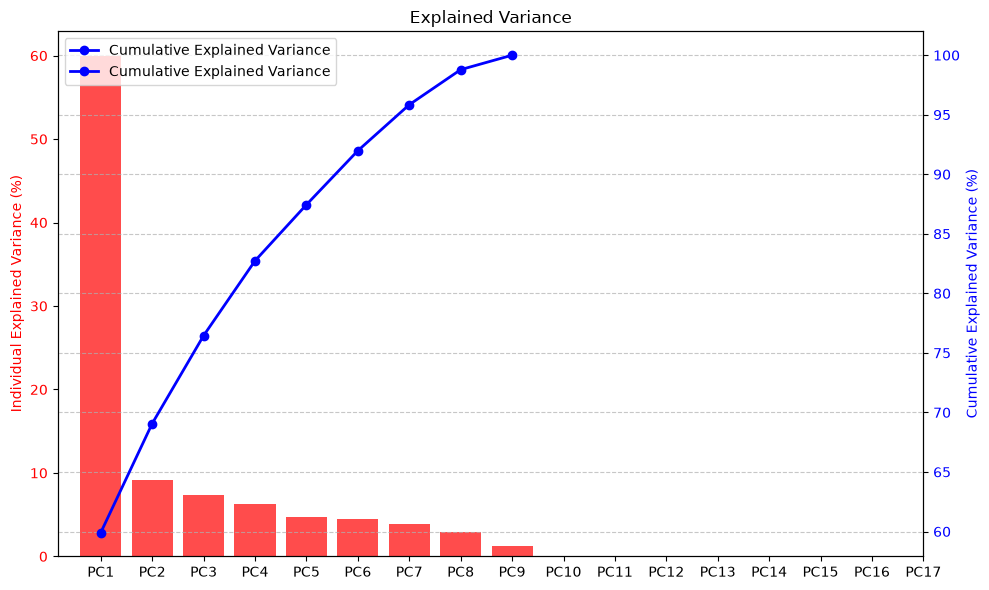

In [73]:
# Explained variance percentage
plt.figure(figsize = (10, 6))

# Create a bar chart for individual explained variance
plt.bar(x = range(1, 10), 
        height = pca_model.explained_variance_ratio_ * 100,
        color = 'red', 
        alpha = 0.7,
        label='Individual Explained Variance')

# Set up primary y-axis labels
plt.ylabel('Individual Explained Variance (%)', color='red')
plt.tick_params(axis='y', labelcolor='red')

# Create secondary y-axis for cumulative variance
ax2 = plt.gca().twinx()

# Add cumulative explained variance line on secondary y-axis
cumulative = np.cumsum(pca_model.explained_variance_ratio_) * 100
ax2.plot(range(1, 10), cumulative, 'o-', color='blue', linewidth=2, 
         label='Cumulative Explained Variance')
ax2.set_ylabel('Cumulative Explained Variance (%)', color='blue')
ax2.tick_params(axis='y', labelcolor='blue')

# Common settings
plt.title('Explained Variance')
plt.xlabel('Principal Components')
plt.xticks(ticks = range(1, 18), labels = ['PC' + str(_) for _ in range(1, 18)])
plt.grid(True, linestyle='--', alpha=0.7)

# Add legend for both plots
lines1, labels1 = plt.gca().get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

In [74]:
# Train model on training set
best_n_components = 4

Model_7 = svc.fit(X_train_pc[:,:best_n_components], y_train)

# Prediction with test data
y_test_prediction_7 = Model_7.predict(X_test_pc[:,:best_n_components])

y_test_prediction_7

# Add results to the DataFrame


array([1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1,
       1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0,
       0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0,
       0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1,
       0, 1, 0, 0, 1, 0, 1])

In [75]:
y_test

126    1
21     1
83     0
133    0
288    1
      ..
444    0
370    0
282    1
637    0
658    1
Name: Class, Length: 139, dtype: int64

In [76]:

Results = pd.concat([Results, 
                             pd.DataFrame({'Accuracy': round(accuracy_score(y_test, y_test_prediction_7), 2),
                                          'Precision': round(precision_score(y_test, y_test_prediction_7), 2),
                                          'Recall': round(recall_score(y_test, y_test_prediction_7), 2),
                                          'F1 Score' : round(f1_score(y_test, y_test_prediction_7), 2),
                                          'F2 Score' : round(fbeta_score(y_test, y_test_prediction_7, beta = 2), 2)},                         
                                           index = ['SVC - PCA'])])

Results

,Accuracy,Precision,Recall,F1 Score,F2 Score
kNN - Tuned,0.94,0.94,0.93,0.93,0.93
Logistic Regression - Tuned,0.97,0.96,0.96,0.96,0.96
Decision Tree - Tuned & Pruned,0.92,0.95,0.88,0.92,0.90
Random Forest - Tuned,0.96,0.96,0.96,0.96,0.96
SVC - Tuned,0.94,0.89,0.99,0.94,0.97
SVC - PCA,0.94,0.92,0.96,0.94,0.95
